In [ ]:
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [ ]:
url = 'https://github.com/Koldim2001/test_api/raw/313b43c227594bd165951e471486f473796f9fa8/titanic.csv'
df = pd.read_csv(url)
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [ ]:
df = df.dropna(subset=['Age'])
df = df[['Survived', 'Pclass', 'Age', 'Fare']].rename(columns=str.lower)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 714 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  714 non-null    int64  
 1   pclass    714 non-null    int64  
 2   age       714 non-null    float64
 3   fare      714 non-null    float64
dtypes: float64(2), int64(2)
memory usage: 27.9 KB


In [ ]:
df.fare.describe()

,fare
count,714.000000
mean,34.694514
std,52.918930
min,0.000000
25%,8.050000
50%,15.741700
75%,33.375000
max,512.329200


<Axes: xlabel='fare', ylabel='Count'>

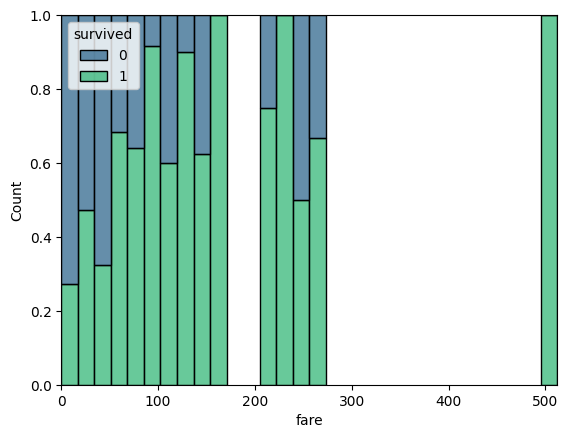

In [ ]:
import seaborn as sns
sns.histplot(data=df, x='fare', hue='survived', multiple='fill', bins=30, palette='viridis')

In [ ]:
df.drop('survived', axis=1)

,pclass,age,fare
0,3,22.0,7.2500
1,1,38.0,71.2833
2,3,26.0,7.9250
3,1,35.0,53.1000
4,3,35.0,8.0500
...,...,...,...
885,3,39.0,29.1250
886,2,27.0,13.0000
887,1,19.0,30.0000
889,1,26.0,30.0000


Лучшие параметры: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 2}
Лучшая точность на кросс-валидации: 0.7267

              precision    recall  f1-score   support

Not Survived       0.69      0.80      0.74        82
    Survived       0.66      0.51      0.57        61

    accuracy                           0.68       143
   macro avg       0.67      0.66      0.66       143
weighted avg       0.68      0.68      0.67       143



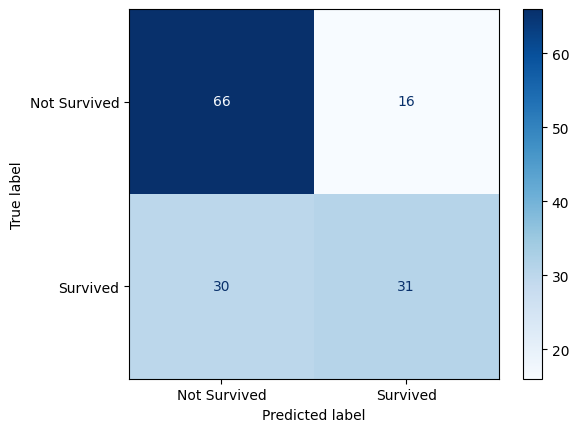

In [ ]:

# 1. Готовим данные (как обычно)
train, test = train_test_split(df, test_size=0.2)
X_train, y_train = train.drop('survived', axis=1), train['survived']
X_test, y_test = test.drop('survived', axis=1), test['survived']

# 2. Задаем «сетку» параметров, которые хотим протестировать
param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 10, 50, 100, 150],
    'criterion': ['gini', 'entropy'] # можно добавить и другие параметры дерева
}

# 3. Создаем базовую модель и запускаем поиск
# cv=5 означает кросс-валидацию по 5 блокам (данные поделятся на 5 частей для честной проверки)
grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

# 4. Выводим лучшие параметры
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучшая точность на кросс-валидации: {grid_search.best_score_:.4f}\n")

# 5. Оцениваем лучшую модель на тестовых данных
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

# Отчет и матрица ошибок
classes = ['Not Survived', 'Survived']
print(classification_report(y_test, y_pred, target_names=classes))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=classes, cmap=plt.cm.Blues)
plt.show()

# 6. Сохраняем лучшую модель
with open('best_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)